# Import Data 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
train_df = pd.read_csv("../data/train-test.csv")

print(f"Dataset shape: {train_df.shape}")
print("\n--- First 5 rows ---")
display(train_df.head())

print("\n--- Data Types & Missing Values ---")
print(train_df.info())

print("\n--- Summary Statistics of Numerical Columns ---")
display(train_df.describe())

Dataset shape: (48000, 14)

--- First 5 rows ---


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28



--- Data Types & Missing Values ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB
None

--- Summary Statistics of Numerical Columns ---


,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,1.083387,2.062468,2373.980682
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,0.168091,0.291391,1486.493245
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,1.467780,3.610350,25533.000000


# EDA

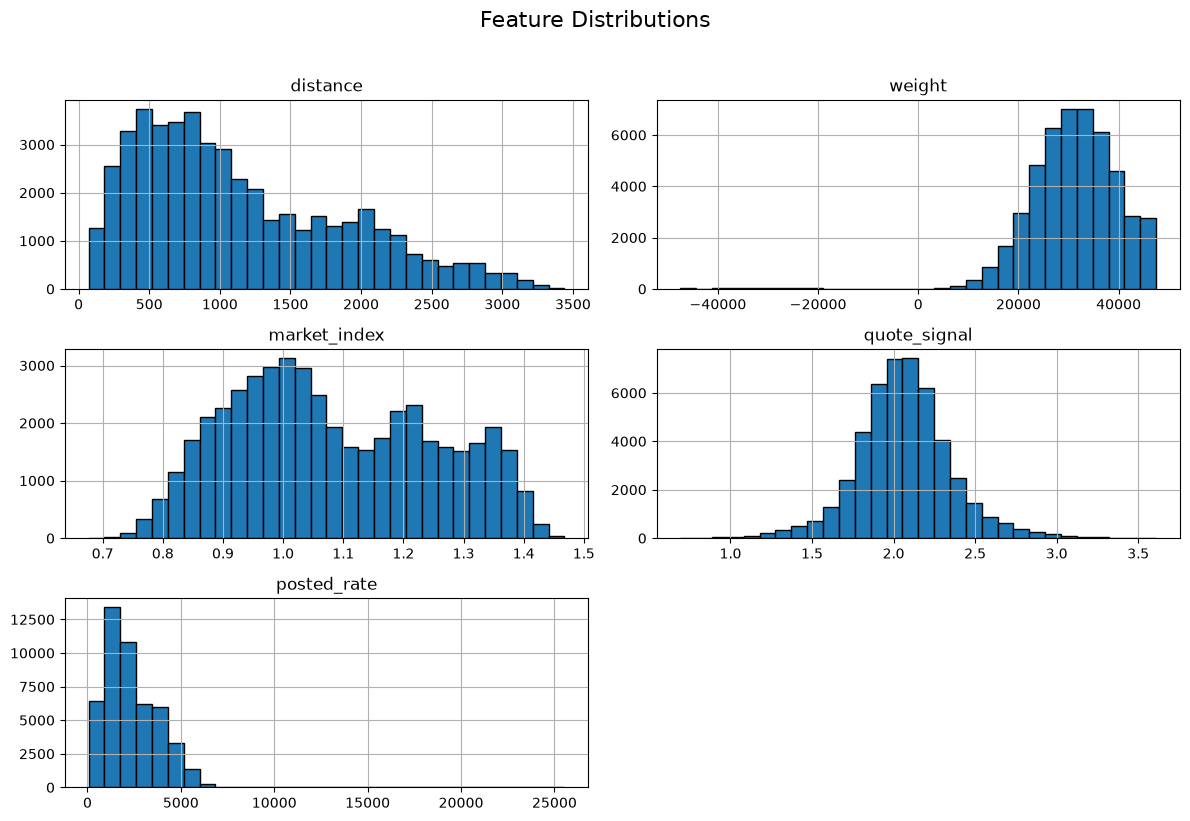

In [2]:
import matplotlib.pyplot as plt

# Select the columns you want to inspect
cols_to_plot = ['distance', 'weight', 'market_index', 'quote_signal', 'posted_rate']

# Plot histograms for all selected columns at once
train_df[cols_to_plot].hist(bins=30, figsize=(12, 8), edgecolor='black')
plt.suptitle("Feature Distributions", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# Preprocessing

In [3]:
# Convert any negative weights to their absolute value
train_df['weight'] = train_df['weight'].abs()

### Filling Missing Values

In [4]:
import pandas as pd

# 1. Fill missing weights with the median weight of the same equipment type
train_df['weight'] = train_df['weight'].fillna(
    train_df.groupby('equipment')['weight'].transform('median')
)

# 2. Safety fallback: If any equipment type has NO weights at all, fill remaining NaNs with the global median
train_df['weight'] = train_df['weight'].fillna(train_df['weight'].median())

# Verify that no missing weights remain
print("Remaining missing weights:", train_df['weight'].isna().sum())

Remaining missing weights: 0


In [5]:
# 1. Ensure date is parsed
train_df['date'] = pd.to_datetime(train_df['date'])
train_df['month'] = train_df['date'].dt.month
train_df['dayofweek'] = train_df['date'].dt.dayofweek

# 2. Fill missing market_index using the median of the same route and month
train_df['market_index'] = train_df['market_index'].fillna(
    train_df.groupby(['pickup', 'delivery', 'month'])['market_index'].transform('median')
)

# 3. Fallback: If route+month combo is completely missing, fill by route alone
train_df['market_index'] = train_df['market_index'].fillna(
    train_df.groupby(['pickup', 'delivery'])['market_index'].transform('median')
)

# 4. Final safety fallback: Global median
train_df['market_index'] = train_df['market_index'].fillna(train_df['market_index'].median())

# Verify that no missing weights remain
print("Remaining missing market_index:", train_df['market_index'].isna().sum())

Remaining missing market_index: 0


### Outlier Handling

In [6]:
# 1. Calculate the median rate for each route
train_df['lane_median'] = train_df.groupby(['pickup', 'delivery'])['posted_rate'].transform('median')

# 2. Calculate absolute deviation and lane MAD (Median Absolute Deviation) vectorially
train_df['abs_dev'] = (train_df['posted_rate'] - train_df['lane_median']).abs()
train_df['lane_mad'] = train_df['abs_dev'].groupby([train_df['pickup'], train_df['delivery']]).transform('median')

# Fallback: Prevent division by zero if all rates in a lane are identical (MAD = 0)
train_df['lane_mad'] = train_df['lane_mad'].replace(0, np.nan).fillna(1.0)

# 3. Compute the robust outlier score (similar to your apply logic)
train_df['outlier_score'] = train_df['abs_dev'] / train_df['lane_mad']

# 4. If the score is >= 6.5, replace the posted_rate with the lane median. Otherwise, keep it.
train_df['posted_rate'] = np.where(
    train_df['outlier_score'] >= 6.5, 
    train_df['lane_median'], 
    train_df['posted_rate']
)

# Reset index cleanly
train_df = train_df.reset_index(drop=True)

### Haversine and Distance Correlation

In [7]:
import numpy as np

def haversine(lat1, lon1, lat2, lon2, unit='miles'):
    # Convert latitude and longitude from degrees to radians
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    
    # Differences
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    
    # Haversine formula
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    
    # Radius of Earth in kilometers or miles
    r = 3959.0 if unit == 'miles' else 6371.0
    
    return r * c

In [8]:
train_df['distance'].corr(haversine(train_df['pickup_lat'], 
                                    train_df['pickup_lon'], 
                                    train_df['delivery_lat'], 
                                    train_df['delivery_lon'], 
                                    unit='miles')
                         )

np.float64(0.9995349596237124)

In [9]:
pd.set_option('display.max_columns', None)

# Cross Validation - Model Selection

In [10]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import LinearSVR
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

# 1. Prepare Data & Categorical Encoding
df_model = train_df.copy()

# Create date helper columns globally on df_model so CV logging can see them
df_model['_temp_date'] = pd.to_datetime(df_model['date'])
df_model['_year_month'] = df_model['_temp_date'].dt.to_period('M')

if 'dayofweek' not in df_model.columns and 'date' in df_model.columns:
    df_model['dayofweek'] = pd.to_datetime(df_model['date']).dt.dayofweek

# Define exact feature list requested
features = ['distance', 'equipment', 'weight', 'market_index', 'quote_signal', 'dayofweek']
target_col = 'posted_rate'

# Keep requested features + target + date + _year_month helper
required_cols = features + [target_col, 'date', '_year_month']
df_model = df_model[[col for col in required_cols if col in df_model.columns]]

# Encode categorical columns
cat_cols = ['equipment', 'dayofweek']
cat_cols = [col for col in cat_cols if col in features]

for col in cat_cols:
    df_model[col] = df_model[col].astype(str)
    encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    df_model[col] = encoder.fit_transform(df_model[[col]])

X = df_model[features]
y = df_model[target_col]

# 2. Define the Rolling CV Function
def rolling_month_cv(df, date_col='date', train_window=5):
    unique_months = sorted(df['_year_month'].unique())
    
    splits = []
    for i in range(len(unique_months) - train_window):
        train_months = unique_months[i : i + train_window]
        val_month = unique_months[i + train_window]
        
        train_idx = df[df['_year_month'].isin(train_months)].index.to_numpy()
        val_idx = df[df['_year_month'] == val_month].index.to_numpy()
        
        if len(train_idx) > 0 and len(val_idx) > 0:
            splits.append((train_idx, val_idx))
    return splits

cv_splits = rolling_month_cv(df_model, date_col='date', train_window=5)

# 3. Define the Models to Test
models = {
    "Linear Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LinearRegression())
    ]),
    "Linear SVR": Pipeline([
        ('scaler', StandardScaler()),
        ('svr', LinearSVR(C=1.0, max_iter=3000, random_state=42))
    ]),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
    "XGBoost": xgb.XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=6, random_state=42, n_jobs=-1),
    "LightGBM": lgb.LGBMRegressor(n_estimators=1000, learning_rate=0.03, num_leaves=31, random_state=42, n_jobs=-1, verbose=-1)
}

# 4. Evaluation Loop with Detailed Printouts
results = {}

for name, model in models.items():
    print(f"\n================ Training and Evaluating: {name} ================")
    rmse_scores = []
    mae_scores = []
    
    for fold, (train_idx, val_idx) in enumerate(cv_splits):
        X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
        X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
        
        # Identify exact month ranges for logging
        train_months_list = sorted(df_model.loc[train_idx, '_year_month'].unique())
        val_month_val = df_model.loc[val_idx, '_year_month'].iloc[0]
        
        print(f"  [Fold {fold+1}]")
        print(f"    -> Train Months: {train_months_list[0]} to {train_months_list[-1]} ({len(train_idx):,} rows)")
        print(f"    -> Val Month:    {val_month_val} ({len(val_idx):,} rows)")
        
        # Fit model
        model.fit(X_train, y_train)
        
        # Predict
        preds = model.predict(X_val)
        
        # Compute metrics
        rmse = np.sqrt(mean_squared_error(y_val, preds))
        mae = mean_absolute_error(y_val, preds)
        
        print(f"    -> Metrics   -> RMSE: {rmse:.4f} | MAE: {mae:.4f}")
        
        rmse_scores.append(rmse)
        mae_scores.append(mae)
    
    results[name] = {
        "Mean RMSE": np.mean(rmse_scores),
        "Std RMSE": np.std(rmse_scores),
        "Mean MAE": np.mean(mae_scores),
        "Std MAE": np.std(mae_scores)
    }

# 5. Display Summary Leaderboard
summary_df = pd.DataFrame(results).T
print("\n================ MODEL PERFORMANCE LEADERBOARD ================")
print(summary_df.sort_values(by="Mean RMSE"))


================ Training and Evaluating: Linear Regression ================
  [Fold 1]
    -> Train Months: 2025-01 to 2025-05 (24,023 rows)
    -> Val Month:    2025-06 (4,783 rows)
    -> Metrics   -> RMSE: 182.8344 | MAE: 133.6181
  [Fold 2]
    -> Train Months: 2025-02 to 2025-06 (23,888 rows)
    -> Val Month:    2025-07 (4,912 rows)
    -> Metrics   -> RMSE: 133.7242 | MAE: 96.5992
  [Fold 3]
    -> Train Months: 2025-03 to 2025-07 (24,463 rows)
    -> Val Month:    2025-08 (4,759 rows)
    -> Metrics   -> RMSE: 124.1060 | MAE: 95.3167
  [Fold 4]
    -> Train Months: 2025-04 to 2025-08 (24,186 rows)
    -> Val Month:    2025-09 (4,670 rows)
    -> Metrics   -> RMSE: 153.0430 | MAE: 119.7281
  [Fold 5]
    -> Train Months: 2025-05 to 2025-09 (24,037 rows)
    -> Val Month:    2025-10 (4,853 rows)
    -> Metrics   -> RMSE: 123.3653 | MAE: 93.9540

================ Training and Evaluating: Linear SVR ================
  [Fold 1]
    -> Train Months: 2025-01 to 2025-05 (24,023 rows)

# Train - Test Model

In [11]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Prepare Data & Ensure Date Periods Exist
df_model = train_df.copy()
df_model['_temp_date'] = pd.to_datetime(df_model['date'])
df_model['_year_month'] = df_model['_temp_date'].dt.to_period('M')

if 'dayofweek' not in df_model.columns and 'date' in df_model.columns:
    df_model['dayofweek'] = df_model['date'].dt.dayofweek

features = ['distance', 'equipment', 'weight', 'market_index', 'quote_signal', 'dayofweek']
target_col = 'posted_rate'

# Encode categorical columns so LightGBM receives strictly numeric data
cat_cols = ['equipment', 'dayofweek']
for col in cat_cols:
    if col in df_model.columns:
        df_model[col] = df_model[col].astype(str)
        encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
        df_model[col] = encoder.fit_transform(df_model[[col]]).astype(float)

# Force all features to be numeric to prevent any object/string dtype errors
for col in features:
    if col in df_model.columns:
        df_model[col] = pd.to_numeric(df_model[col], errors='coerce').fillna(-1)

X = df_model[features]
y = df_model[target_col]

# 2. Split: All months except the last for training, the absolute last month for validation
unique_months = sorted(df_model['_year_month'].unique())
train_months = unique_months[:-1]
val_month = unique_months[-1]

train_idx = df_model[df_model['_year_month'].isin(train_months)].index.to_numpy()
val_idx = df_model[df_model['_year_month'] == val_month].index.to_numpy()

print("================ FINAL TRAIN / VAL SPLIT CONFIGURATION ================")
print(f"Training Period: Months {train_months[0]} through {train_months[-1]} ({len(train_idx):,} rows)")
print(f"Validation Period (Last Month): {val_month} ({len(val_idx):,} rows)")

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

# 3. Initialize and Train LightGBM
print("\nTraining LightGBM on historical months...")
lgb_model = lgb.LGBMRegressor(
    n_estimators=1000, 
    learning_rate=0.03, 
    num_leaves=31, 
    random_state=42, 
    n_jobs=-1, 
    verbose=-1
)

lgb_model.fit(X_train, y_train)

# 4. Predict and Evaluate on the Last Month
print(f"Generating predictions for the validation month ({val_month})...")
preds = lgb_model.predict(X_val)

final_rmse = np.sqrt(mean_squared_error(y_val, preds))
final_mae = mean_absolute_error(y_val, preds)

print("\n================ FINAL VALIDATION PERFORMANCE ================")
print(f"Target Month : {val_month}")
print(f"Root Mean Squared Error (RMSE) : {final_rmse:.4f}")
print(f"Mean Absolute Error (MAE)      : {final_mae:.4f}")

# Save predictions for submission or charting
validation_predictions = pd.DataFrame({
    'load_id': df_model.loc[val_idx, 'load_id'] if 'load_id' in df_model.columns else val_idx,
    'predicted_rate': preds
})

================ FINAL TRAIN / VAL SPLIT CONFIGURATION ================
Training Period: Months 2025-01 through 2025-09 (43,147 rows)
Validation Period (Last Month): 2025-10 (4,853 rows)

Training LightGBM on historical months...
Generating predictions for the validation month (2025-10)...

================ FINAL VALIDATION PERFORMANCE ================
Target Month : 2025-10
Root Mean Squared Error (RMSE) : 106.0709
Mean Absolute Error (MAE)      : 76.4368


# Error Analysis

In [12]:
# 1. Generate predictions for the current validation fold/set
val_preds = model.predict(X_val)

# 2. Convert predictions to a Pandas Series aligned with X_val's index
val_preds_series = pd.Series(val_preds, index=X_val.index)

# 3. Calculate absolute errors
errors = np.abs(y_val - val_preds_series)

# 4. Find the worst 10 predictions
worst_indices = errors.nlargest(10).index

display(X_val.loc[worst_indices])
print("\nActual vs Predicted for worst rows:")
display(pd.DataFrame({
    'Actual': y_val.loc[worst_indices], 
    'Predicted': val_preds_series.loc[worst_indices], 
    'Error': errors.loc[worst_indices]
}))

,distance,equipment,weight,market_index,quote_signal,dayofweek
46643,2416.0,2.0,36653.0,1.08204,1.88368,3.0
44103,3185.8,0.0,20056.0,0.94464,2.27632,1.0
47984,3396.6,0.0,43205.0,1.01436,2.26942,4.0
46570,2204.7,2.0,36190.0,1.05650,2.03321,2.0
45051,2442.4,2.0,30742.0,0.84900,2.08630,0.0
43346,2391.8,2.0,42945.0,0.99040,2.18707,3.0
46173,2490.9,0.0,22411.0,0.87879,2.40555,0.0
45700,3308.4,2.0,23624.0,0.98831,2.13077,4.0
45285,1590.7,0.0,30170.0,0.93687,2.10491,1.0
44608,1787.3,2.0,32588.0,1.07150,1.85888,4.0



Actual vs Predicted for worst rows:


,Actual,Predicted,Error
46643,4117.400,5153.810242,1036.410242
44103,6527.780,5497.423023,1030.356977
47984,6482.040,5769.017235,713.022765
46570,4090.140,4711.393737,621.253737
45051,4401.810,4977.261859,575.451859
43346,4754.030,5308.614084,554.584084
46173,4806.640,4270.299202,536.340798
45700,6710.480,6198.692236,511.787764
45285,3527.990,3046.372923,481.617077
44608,3422.385,3881.583139,459.198139


(array([1.327e+03, 9.580e+02, 6.960e+02, 5.190e+02, 3.790e+02, 2.730e+02,
        2.200e+02, 1.430e+02, 1.090e+02, 6.400e+01, 5.400e+01, 2.700e+01,
        2.400e+01, 1.400e+01, 1.200e+01, 9.000e+00, 5.000e+00, 2.000e+00,
        4.000e+00, 1.000e+00, 0.000e+00, 3.000e+00, 1.000e+00, 1.000e+00,
        1.000e+00, 1.000e+00, 1.000e+00, 1.000e+00, 0.000e+00, 1.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 2.000e+00]),
 array([1.07877037e-02, 2.07387768e+01, 4.14667659e+01, 6.21947550e+01,
        8.29227440e+01, 1.03650733e+02, 1.24378722e+02, 1.45106711e+02,
        1.65834700e+02, 1.86562689e+02, 2.07290679e+02, 2.28018668e+02,
        2.48746657e+02, 2.69474646e+02, 2.90202635e+02, 3.10930624e+02,
        3.31658613e+02, 3.52386602e+02, 3.73114591e+02, 3.93842580e+02,
        4.145705

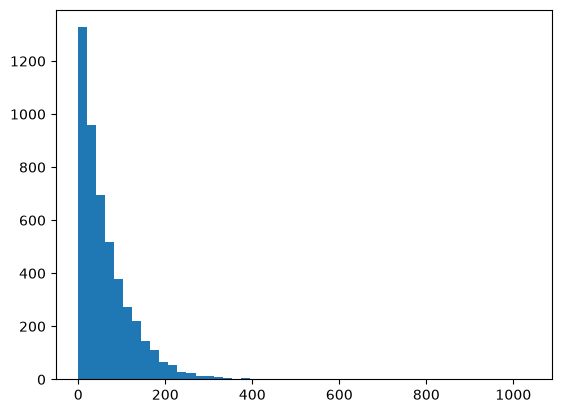

In [13]:
plt.hist((errors), bins=50)

In [14]:
indice = 46643
normal_pts = train_df[(train_df['pickup'] == train_df.loc[[indice]]['pickup'].values[0]) & 
                      (train_df['delivery'] == train_df.loc[[indice]]['delivery'].values[0])]
normal_pts

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,month,dayofweek,lane_median,abs_dev,lane_mad,outlier_score
15761,TR-015762,Dayton,San Francisco,39.87206,-85.62931,35.1967,-121.69849,2303.5,Dry Van,19708.0,2025-04-09,1.18233,2.48994,4036.57,4,2,4117.4,80.83,80.83,1.000000
38194,TR-038195,Dayton,San Francisco,39.87206,-85.62931,35.1967,-121.69849,2264.1,Dry Van,30207.0,2025-08-30,0.92705,2.12231,4117.40,8,5,4117.4,0.00,80.83,0.000000
46643,TR-046644,Dayton,San Francisco,39.87206,-85.62931,35.1967,-121.69849,2416.0,Reefer,36653.0,2025-10-23,1.08204,1.88368,4117.40,10,3,4117.4,1249.81,80.83,15.462205


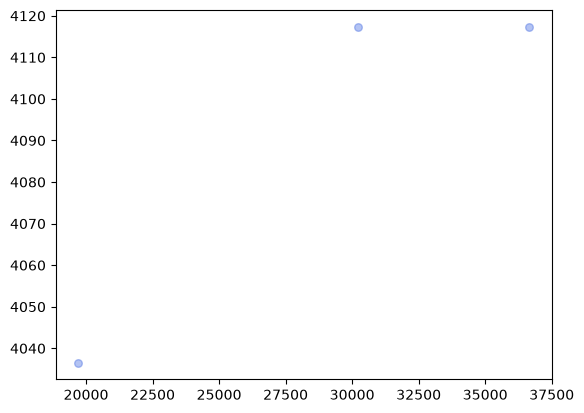

In [15]:
plt.scatter(
    normal_pts['weight'], 
    normal_pts['posted_rate'], 
    color='royalblue', 
    alpha=0.4, 
    s=30, 
    label='Normal Loads'
)